In [1]:
import sys # for automation and parallelization: set manual to false when run by a launcher
import json
MANUAL, SCENARIO = (True, 'base') if 'ipykernel' in sys.argv[0]\
     else (False, json.loads(sys.argv[1])['scenario'])

In [2]:
import sys
sys.path.insert(0, r'../../../quetzal')

from quetzal.model import stepmodel, connectionscanmodel
from quetzal.io import excel
import pandas as pd
from shapely import geometry
# import osmnx as ox
import geopandas as gpd
import os
# import statsmodels.api as statm
# import statsmodels.formula.api as smf
import matplotlib.pyplot as plt #pour les tracés de courbes
import seaborn as sns

In [3]:
qpath = r'../../'
ipath = qpath + r'inputs/'
mpath = qpath + r'models/{}/'.format(SCENARIO)

In [4]:
var = excel.read_var(ipath + r'parameters.xlsx', scenario=SCENARIO)

# COEF GENERATION
ALPHA_HOUSEHOLD = var['step_generation']['alpha_household']
ALPHA_WORKPLACE = var['step_generation']['alpha_workplace']

# COEF MORNING TRAVEL
COEFF_MORNING = var['step_generation']['coeff_morning']

# COEF DISTRIBUTION
INTRA_AREA_TO_DISTANCE_FACTOR = var['step_distribution']['intra_area_to_distance_factor']

DISTRIBUTION_POWER = var['step_distribution']['distribution_power']
INTRAZONAL_SPEED = var['step_distribution']['intrazonal_speed'] # for intrazonal time

# EXTERNAL_MATRIX
EXTERNAL_PT_SHARE = var['step_generation']['external_pt_share']

# MOTO / OCCUPANCY
MOTORCYCLE_SHARE = var['step_generation']['motorcycle_share']
PV_OCCUPANCY_RATE = var['step_generation']['pv_occupancy_rate']
MOTORIZATION_RATE_FACTOR = var['step_generation']['motorization_rate_factor']

In [5]:
if var['run_mode']['mode'] != 'timetables':
    sm = stepmodel.read_zippedpickles(mpath + r'pathfinders')
else:
    sm = connectionscanmodel.read_zippedpickles(mpath + r'pathfinders')

zone_to_road: 100%|██████████| 21/21 [00:02<00:00,  8.97it/s]


<Axes: >

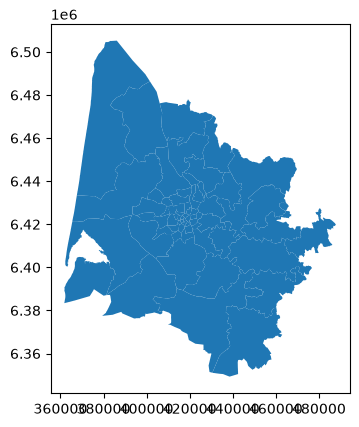

In [6]:
### TODO: taille des ménages + csp à ajouter?
sm.zones.plot()

# Génération

Already included in zone inputs

In [7]:
# TODO Louison corriger mon contournement car je n’ai pas la bonne input
sm.zones['emission'] = 1#sm.zones['nb household']
sm.zones['attraction'] = 1#sm.zones['nb workplaces']*(sm.zones['nb household'].sum()/sm.zones['nb workplaces'].sum())

# Distribution

In [8]:
sm.zones[['attraction', 'emission']].sum()

attraction    68
emission      68
dtype: int64

In [9]:
all_los = pd.DataFrame(
    index=pd.MultiIndex.from_product(
        [sm.zones.index, sm.zones.index],
        names=['origin', 'destination']
    )
)

deterrence_matrix = all_los.join(
    sm.los.loc[sm.los['pathfinder_session'].isin(['car_aon', 'intrazonal'])].groupby(['origin', 'destination'])['length'].min()
).fillna(1e9)

deterrence_matrix['length'] = deterrence_matrix['length'] ** (-DISTRIBUTION_POWER)

# distribution
sm.step_distribution(
    deterrence_matrix=deterrence_matrix.unstack(),
    intrazonal=True
)
# TODO Louison: attention à l’ordre des zones et index à cette étapes: [zone_1, zone_2, zone_3, …] peut devenir [zone_1, zone_10, zone_11, …]

# EXPORT

In [10]:
sm.to_zippedpickles(mpath + r'/generation_distribution')

zone_to_road: 100%|██████████| 21/21 [00:04<00:00,  4.64it/s]   


In [12]:
end_of_notebook

NameError: name 'end_of_notebook' is not defined

# insight

In [ ]:
from shapely.geometry import LineString
import numpy as np
intrazone_distances = (sm.zones.area ** 0.5) * INTRA_AREA_TO_DISTANCE_FACTOR
zone_geom = sm.zones['geometry'].centroid.to_dict()

sm.volumes['distance'] = sm.volumes.apply(
    lambda r: LineString([zone_geom[r['origin']], zone_geom[r['destination']]]).length,
    1
)

sm.volumes.loc[sm.volumes['origin']==sm.volumes['destination'], 'distance'] = sm.volumes.loc[sm.volumes['origin']==sm.volumes['destination']].apply(
    lambda x: intrazone_distances[x['origin']], 1
) 

In [ ]:
sm.volumes['volume'] = sm.volumes['pt_captive'] + sm.volumes['car_owners'] + sm.volumes['moto_owners']

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
bins=np.arange(0, 8000, 350)

ax.hist(
    [sm.volumes['distance'], sm.volumes['distance'], sm.volumes['distance']],
    bins=bins, 
    weights=[
        sm.volumes['volume'] / sm.volumes['volume'].sum(),
        sm.volumes['pt_captive'] / sm.volumes['pt_captive'].sum(),
        sm.volumes['car_owners'] / sm.volumes['car_owners'].sum()
    ],
    label=['volume', 'pt_captive', 'car_owners'],
    rwidth=0.8
)
plt.legend()

# Compare with SL

In [ ]:
sm = stepmodel.read_zippedpickles(mpath + r'{}/generation_distribution'.format(SCENARIO))

In [ ]:
# fake car assignment
# TODO: remove walk volumes:
sm.car_los[('pt_captive', 'probability')] = 1
sm.car_los[('car_owners', 'probability')] = 1

sm.car_los.loc[sm.car_los['length']<5000, [('pt_captive', 'probability')]] = 0.6
sm.car_los.loc[sm.car_los['length']<5000, [('car_owners', 'probability')]] = 0.7

sm.car_los.loc[sm.car_los['length']<3000, [('pt_captive', 'probability')]] = 0.4
sm.car_los.loc[sm.car_los['length']<3000, [('car_owners', 'probability')]] = 0.5

sm.car_los.loc[sm.car_los['length']<2000, [('pt_captive', 'probability')]] = 0.2
sm.car_los.loc[sm.car_los['length']<2000, [('car_owners', 'probability')]] = 0.3

sm.car_los.loc[sm.car_los['length']<1000, [('pt_captive', 'probability')]] = 0.05
sm.car_los.loc[sm.car_los['length']<1000, [('car_owners', 'probability')]] = 0.1

sm.car_los.loc[sm.car_los['length']<500, [('pt_captive', 'probability')]] = 0
sm.car_los.loc[sm.car_los['length']<500, [('car_owners', 'probability')]] = 0

sm.segments = ['car_owners', 'pt_captive']
sm.step_car_assignment()

In [ ]:
sm.los = sm.car_los.copy()

In [ ]:
sm.compute_los_volume()

In [ ]:
(sm.los[['car_owners', 'pt_captive', 'volume']].sum()) / sm.volumes[['car_owners', 'pt_captive']].sum().sum()

In [ ]:
sl_counts = pd.read_csv(ipath + r'calibration/{}_sl_mph.csv'.format(CITY), sep=';')

In [ ]:
sl_counts.columns

In [ ]:
sl_counts = sl_counts.merge(sm.road_links[['a', 'b']].reset_index(), on=['a', 'b'], how='left')
sl_counts['pt'] = sl_counts[['rickshaws_3', 'qing qis', 'minibuses', 'suzukis', 'hiaces', 'buses']].T.sum()
sl_counts['pv'] = sl_counts[['private_car', '2_wheelers', 'taxies']].T.sum()

In [ ]:
sl_counts = sl_counts.merge(
    sm.road_links[[('car_owners', 'car'), ('pt_captive', 'car')]].reset_index(),
    on='index', how='left'
)
sl_counts['model_pt'] = sl_counts[('pt_captive', 'car')]
sl_counts['model_pv'] = sl_counts[('car_owners', 'car')]

In [ ]:
# Calcul du GEH
def geh(o,m):
    if o==m:
        return 0
    else:
        return (2*(o-m)**2/(o+m))**0.5

In [ ]:
sl_counts[['pv', 'model_pv']].sum()

In [ ]:
sl_counts[['pt', 'model_pt']].sum()

In [ ]:
sl_counts['geh_pt'] = sl_counts.apply(lambda r: geh(r['pt'], r['model_pt']), 1)
sl_counts['geh_pv'] = sl_counts.apply(lambda r: geh(r['pv'], r['model_pv']), 1)

import numpy as np
# plot
m = 15000

ax = sl_counts.plot(
    x='pt',
    y='model_pt', kind='scatter',
    ylim=[0, m],
    xlim=[0, m],
    figsize=(8,8)
)

sl_counts[sl_counts['geh_pt']>8].apply(
    lambda r: plt.annotate(
        text=int(r['geh_pt']),
        xy=(r['pt'], r['model_pt'])
    ),
    1
)

sl_counts.plot(
    x='pv',
    y='model_pv', kind='scatter',
    ylim=[0, m],
    xlim=[0, m],
    # figsize=(8,8),
    ax=ax,
    color='r'
)

sl_counts[sl_counts['geh_pt']>8].apply(
    lambda r: plt.annotate(
        text=int(r['geh_pv']),
        xy=(r['pv'], r['model_pv']),
        color='r'
    ),
    1
)

plt.plot(np.arange(0,m,100), np.arange(0,m,100), color='r', linestyle='--')

In [ ]:
sm.road_links.columns

In [ ]:
from syspy.syspy_utils import data_visualization as dv
rl = sm.road_links.copy()
rl['load'] = rl[('all', 'car')]
rl = rl.loc[rl['load']>0]
rl['label'] = ''

ax = dv.bandwidth(
    rl, 'load', figsize=(20,  20), legend=True, label_column='label', 
    max_linewidth_meters=200, power=0.5, max_value=8000, cmap='Spectral_r',
    offset_direction='left'
)

# ax = dv.add_raster(ax, raster, keep_ax_limits=False)

# if True:
#     ax.set_xlim(xlim)
#     ax.set_ylim(ylim)